# Live Human Pose Estimation with OpenVINO™

This notebook demonstrates live pose estimation with OpenVINO, using the OpenPose [human-pose-estimation-0001](https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001) model from [Open Model Zoo](https://github.com/openvinotoolkit/open_model_zoo/). Final part of this notebook shows live inference results from a webcam. Additionally, you can also upload a video file.

> **NOTE**: To use a webcam, you must run this Jupyter notebook on a computer with a webcam. If you run on a server, the webcam will not work. However, you can still do inference on a video in the final step.

## Imports

In [92]:
import collections
import sys
import time
from pathlib import Path

import cv2
import numpy as np
from IPython import display
from numpy.lib.stride_tricks import as_strided
from openvino.runtime import Core

from decoder import OpenPoseDecoder

sys.path.append("../utils")
import notebook_utils as utils

## The model

### Download the model

Use the `download_file`, a function from the `notebook_utils` file. It automatically creates a directory structure and downloads the selected model.

If you want to download another model, replace the name of the model and precision in the code below. 

> **NOTE**: This may require a different pose decoder.

In [93]:
# A directory where the model will be downloaded.
base_model_dir = Path("model")

# The name of the model from Open Model Zoo.
model_name = "human-pose-estimation-0001"
# Selected precision (FP32, FP16, FP16-INT8).
precision = "FP32"

model_path = base_model_dir / "intel" / model_name / precision / f"{model_name}.xml"

if not model_path.exists():
    model_url_dir = f"https://storage.openvinotoolkit.org/repositories/open_model_zoo/2022.1/models_bin/3/{model_name}/{precision}/"
    utils.download_file(model_url_dir + model_name + '.xml', model_path.name, model_path.parent)
    utils.download_file(model_url_dir + model_name + '.bin', model_path.with_suffix('.bin').name, model_path.parent)

In [94]:
model_path

WindowsPath('model/intel/human-pose-estimation-0001/FP32/human-pose-estimation-0001.xml')

### Load the model

Downloaded models are located in a fixed structure, which indicates a vendor, the name of the model and a precision.

Only a few lines of code are required to run the model. First, initialize OpenVINO Runtime. Then, read the network architecture and model weights from the `.bin` and `.xml` files to compile it for the desired device.

In [95]:
# Initialize OpenVINO Runtime
ie_core = Core()
# Read the network from a file.
model = ie_core.read_model(model_path)
# Let the AUTO device decide where to load the model (you can use CPU, GPU or MYRIAD as well).
compiled_model = ie_core.compile_model(model=model, device_name="AUTO", config={"PERFORMANCE_HINT": "LATENCY"})

# Get the input and output names of nodes.
input_layer = compiled_model.input(0)
output_layers = compiled_model.outputs

# Get the input size.
height, width = list(input_layer.shape)[2:]

Input layer has the name of the input node and output layers contain names of output nodes of the network. In the case of OpenPose Model, there is 1 input and 2 outputs: pafs and keypoints heatmap.

In [96]:
input_layer.any_name, [o.any_name for o in output_layers]

('data', ['Mconv7_stage2_L1', 'Mconv7_stage2_L2'])

## Processing

### OpenPoseDecoder

To transform the raw results from the neural network into pose estimations, you need Open Pose Decoder. It is provided in the [Open Model Zoo](https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/openvino/model_zoo/model_api/models/open_pose.py) and compatible with the `human-pose-estimation-0001` model.

If you choose a model other than `human-pose-estimation-0001` you will need another decoder (for example, AssociativeEmbeddingDecoder), which is available in the [demos section](https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/openvino/model_zoo/model_api/models/hpe_associative_embedding.py) of Open Model Zoo.

In [97]:
decoder = OpenPoseDecoder()

### Process Results

A bunch of useful functions to transform results into poses.

First, pool the heatmap. Since pooling is not available in numpy, use a simple method to do it directly with numpy. Then, use non-maximum suppression to get the keypoints from the heatmap. After that, decode poses by using the decoder. Since the input image is bigger than the network outputs, you need to multiply all pose coordinates by a scaling factor.

In [98]:
# 2D pooling in numpy (from: https://stackoverflow.com/a/54966908/1624463)
def pool2d(A, kernel_size, stride, padding, pool_mode="max"):
    """
    2D Pooling

    Parameters:
        A: input 2D array
        kernel_size: int, the size of the window
        stride: int, the stride of the window
        padding: int, implicit zero paddings on both sides of the input
        pool_mode: string, 'max' or 'avg'
    """
    # Padding
    A = np.pad(A, padding, mode="constant")

    # Window view of A
    output_shape = (
        (A.shape[0] - kernel_size) // stride + 1,
        (A.shape[1] - kernel_size) // stride + 1,
    )
    kernel_size = (kernel_size, kernel_size)
    A_w = as_strided(
        A,
        shape=output_shape + kernel_size,
        strides=(stride * A.strides[0], stride * A.strides[1]) + A.strides
    )
    A_w = A_w.reshape(-1, *kernel_size)

    # Return the result of pooling.
    if pool_mode == "max":
        return A_w.max(axis=(1, 2)).reshape(output_shape)
    elif pool_mode == "avg":
        return A_w.mean(axis=(1, 2)).reshape(output_shape)


# non maximum suppression
def heatmap_nms(heatmaps, pooled_heatmaps):
    return heatmaps * (heatmaps == pooled_heatmaps)


# Get poses from results.
def process_results2(img, pafs, heatmaps):
    # This processing comes from
    # https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/models/open_pose.py
    pooled_heatmaps = np.array(
        [[pool2d(h, kernel_size=3, stride=1, padding=1, pool_mode="max") for h in heatmaps[0]]]
    )
    nms_heatmaps = heatmap_nms(heatmaps, pooled_heatmaps)

    # Decode poses.
    poses, scores = decoder(heatmaps, nms_heatmaps, pafs)

    output_shape = list(compiled_model.output(index=0).partial_shape)
    output_scale = img.shape[1] / output_shape[3].get_length(), img.shape[0] / output_shape[2].get_length()
    print(output_scale)
    # Multiply coordinates by a scaling factor.
    poses[:, :, :2] *= output_scale
    return poses, scores

# Get poses from results.
def process_results(img, pafs, heatmaps):
    # This processing comes from
    # https://github.com/openvinotoolkit/open_model_zoo/blob/master/demos/common/python/models/open_pose.py
    pooled_heatmaps = np.array(
        [[pool2d(h, kernel_size=3, stride=1, padding=1, pool_mode="max") for h in heatmaps[0]]]
    )
    nms_heatmaps = heatmap_nms(heatmaps, pooled_heatmaps)

    # Decode poses.
    poses, scores = decoder(heatmaps, nms_heatmaps, pafs)
    distances = return_centroids(humans=poses)
    # (x == number of humans) | (y == coco keypoints) | (z == array of x, y and score of that keypoint)
    # Example of output: poses shape => (9, 17, 3) scores shape => (9,)
    # print(poses, scores)

    output_shape = list(compiled_model.output(index=0).partial_shape)
    output_scale = img.shape[1] / output_shape[3].get_length(), img.shape[0] / output_shape[2].get_length()
    # Multiply coordinates by a scaling factor.
    poses[:, :, :2] *= output_scale
    return poses, scores, distances

### Process the distances with visualization

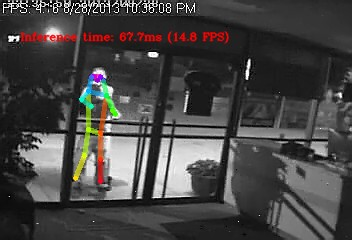

Source ended


In [129]:
import csv
from glob import glob

non_violence_video_paths = glob("./datasets/fight-detection-surv-dataset/nonViolence/*.mp4")
violence_video_paths = glob("./datasets/fight-detection-surv-dataset/violence/*.mp4")

header = ["filename", "frame", "humans_detected", "human_pair", "distance"]

results_file = open('distances_results_fight_surv_dataset_v4_with_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

all_videos = violence_video_paths

for video_file in all_videos:
  run_pose_estimation(writer, video_file, flip=False, use_popup=False, skip_first_frames=0)

# closing the file
results_file.close()

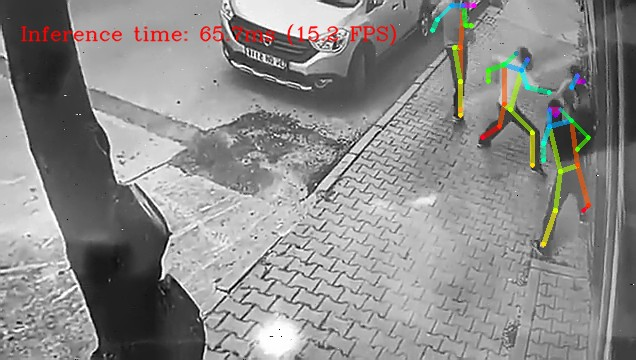

Source ended


In [128]:
# video_file = "https://github.com/mamonraab/Real-Time-Violence-Detection-in-Video-/blob/master/hospital.mp4?raw=true"
video_file = "https://github.com/seymanurakti/fight-detection-surv-dataset/blob/master/fight/fi125.mp4?raw=true"
# video_file = "https://github.com/intel-iot-devkit/sample-videos/blob/master/store-aisle-detection.mp4?raw=true"
run_pose_estimation(csv_results_writer=None, source=video_file, flip=True, use_popup=False, skip_first_frames=0)

### 01: Tests for get Centroid 1 from realtime pose estimation code


In [8]:
from enum import Enum

class CocoPart(Enum):
  Nose = 0
  Neck = 1
  RShoulder = 2
  RElbow = 3
  RWrist = 4
  LShoulder = 5
  LElbow = 6
  LWrist = 7
  RHip = 8
  RKnee = 9
  RAnkle = 10
  LHip = 11
  LKnee = 12
  LAnkle = 13
  REye = 14
  LEye = 15
  REar = 16
  LEar = 17
  Background = 18
CocoPairs = [
  (1, 2), (1, 5), (2, 3), (3, 4), (5, 6), (6, 7), (1, 8), (8, 9), (9, 10), (1, 11),
  (11, 12), (12, 13), (1, 0), (0, 14), (14, 16), (0, 15), (15, 17), (2, 16), (5, 17)
]   # = 19

def return_center_points(npimg, humans, imgcopy=False):
  image_h, image_w = npimg.shape[:2]
  centers = {}

  points=[]
  individuals=[]
  for counter in range(18):
      points.append((0,0))
  for human in humans:
    for i in range(CocoPart.Background.value - 1):
      body_part = human[i] # body_part[0] == x -- body_part[1] == y
      center = (int(body_part[0] * image_w + 0.5), int(body_part[1] * image_h + 0.5))
      centers[i] = center
      points[i] = center
    points_copy = points[:]
    individuals.append(points_copy)

  return individuals

### 02: Tests for get Centroid from skeleton by avering x and y coordinates (CURRENT)

In [99]:
import math

def calculate_centroids_distances(centroids):
  # Calculate distances between centroids
  distances = []
  for i in range(len(centroids)):
    for j in range(len(centroids)):
      if i == j:
        continue
      centroid1 = centroids[i]["centroid"]
      centroid2 = centroids[j]["centroid"]
      human1 = centroids[i]["human_index"]
      human2 = centroids[j]["human_index"]
      x1, y1 = centroid1
      x2, y2 = centroid2
      distance = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2) # Calculating Euclidian Distance 
      distances.append(
        {"human_pair": (human1, human2), "distance": distance}
      )

  return distances
  # # Display or use the distance values
  # for distance in distances:
  #     print(str(distance))

def return_centroids(humans) -> list:
  centroids = []
  for index, keypoints in enumerate(humans):
    if len(keypoints) > 0:
      x_coordinates = keypoints[:, 0]
      y_coordinates = keypoints[:, 1]
      centroid_x = np.mean(x_coordinates)
      centroid_y = np.mean(y_coordinates)
      centroid = (centroid_x, centroid_y)
      centroids.append(
        {"human_index": index, "centroid": centroid}
      ) # { human_index: 1, centroid: (3,0) }

  return calculate_centroids_distances(centroids)

### Filters for PreProcessing

In [132]:
import cv2
import numpy as np

def PM_anisotropic_diffusion(image, iterations, delta, kappa):
    # Convert the input image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Initialize the diffusion tensor
    D = np.ones(gray.shape, dtype=np.float32)

    for i in range(iterations):
        # Compute the gradient of the grayscale image
        grad = cv2.Sobel(gray, cv2.CV_32F, 1, 1)

        # Compute the magnitude and direction of the gradient
        mag = np.abs(grad)
        direction = np.sign(grad)

        # Compute the diffusion tensor
        Dxx = cv2.Sobel(D, cv2.CV_32F, 2, 0)
        Dyy = cv2.Sobel(D, cv2.CV_32F, 0, 2)
        Dxy = cv2.Sobel(D, cv2.CV_32F, 1, 1)
        D = (1 / (1 + ((mag * kappa) / delta)**2)) * \
            (D + delta**2 * (Dxx*direction[0]**2 + 2*Dxy*direction[0]*direction[1] + Dyy*direction[1]**2))

        # Apply the diffusion tensor to the image
        gray = gray + 0.25 * D * (cv2.Laplacian(gray, cv2.CV_32F))

    # Convert the output image back to color
    output = cv2.cvtColor(gray.astype(np.uint8), cv2.COLOR_GRAY2BGR)

    return output

def preprocess_frame_with_filters(image):
  blur_pm = PM_anisotropic_diffusion(image, 80, 0.20, 0.2)
  blur_pm_gray = cv2.cvtColor(blur_pm, cv2.COLOR_BGR2GRAY)
  blur_pm_blur = cv2.GaussianBlur(blur_pm_gray, (5, 5), 0)
  blur_pm_unsharp = cv2.addWeighted(blur_pm_gray, 2.15, blur_pm_blur, -1.1, 1)

  return cv2.cvtColor(blur_pm_unsharp.astype(np.uint8), cv2.COLOR_GRAY2BGR); # Convert the output image back to color

### Teste For Dataset: FIGHT DETECTION IN SURVEILLANCE VIDEOS DATASET

##### Testes With Blur Filter before Sharpen

In [133]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/fight-detection-surv-dataset/violence/*.mp4")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_fight_surv_dataset_v6_with_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=True)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()



Source ended
./datasets/fight-detection-surv-dataset/violence\fi001.mp4 75.52876340018379 6 6.5 13.985
Source ended
./datasets/fight-detection-surv-dataset/violence\fi002.mp4 63.77058105914471 9 7.111111111111111 10.307
Source ended
./datasets/fight-detection-surv-dataset/violence\fi003.mp4 62.64942391287713 8 8.625 13.852
Source ended
./datasets/fight-detection-surv-dataset/violence\fi004.mp4 60.9268244234233 11 7.2727272727272725 10.255
Source ended
./datasets/fight-detection-surv-dataset/violence\fi005.mp4 61.69041307935429 9 4.0 8.002
Source ended
./datasets/fight-detection-surv-dataset/violence\fi006.mp4 62.055760834898265 8 2.75 9.689
Source ended
./datasets/fight-detection-surv-dataset/violence\fi007.mp4 62.68830120968981 7 5.285714285714286 12.579
Source ended
./datasets/fight-detection-surv-dataset/violence\fi008.mp4 61.60589188945536 7 5.571428571428571 13.848
Source ended
./datasets/fight-detection-surv-dataset/violence\fi009.mp4 61.00486551643049 9 5.222222222222222 10.607


In [ ]:
"""
  Code for Testing distances withiout filters
"""

results_file_without_filter = open('average_distances_results_fight_surv_dataset_v2_without_filters.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file_without_filter)

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]
# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_without_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=False)
  average_distances_results_fight_surv_dataset_without_filters.append(average_distance)

# closing the file
results_file_without_filter.close()
print("############# RESULTS #############")
print(f"With Filters: {average_distances_results_fight_surv_dataset_with_filters} ---- Without Filters: {np.mean(average_distances_results_fight_surv_dataset_without_filters)}")

In [135]:
clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITH FILTERS V2: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITH FILTERS V2: fight_surv_dataset 11.64


In [89]:
clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITH FILTERS: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITH FILTERS: fight_surv_dataset 11.765


In [91]:
clean_average_distances_results_fight_surv_dataset_without_filters = [dist for dist in average_distances_results_fight_surv_dataset_without_filters if str(dist) != 'nan']
print("WITHOUT FILTERS: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_without_filters), 3))

WITHOUT FILTERS: fight_surv_dataset 11.586


In [ ]:
clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITH FILTERS V2: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

##### Testes Without Blur Filter before Sharpen

In [105]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/fight-detection-surv-dataset/violence/*.mp4")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_fight_surv_dataset_v3_with_filters_no_blur.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=True)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()

Source ended
./datasets/fight-detection-surv-dataset/violence\fi001.mp4 64.13055729298364 8 6.25 14.959
Source ended
./datasets/fight-detection-surv-dataset/violence\fi002.mp4 60.66074586839693 9 7.0 10.263
Source ended
./datasets/fight-detection-surv-dataset/violence\fi003.mp4 59.98980449069114 8 8.25 13.867
Source ended
./datasets/fight-detection-surv-dataset/violence\fi004.mp4 59.51513960482521 11 7.090909090909091 10.706
Source ended
./datasets/fight-detection-surv-dataset/violence\fi005.mp4 59.96249279227416 9 3.7777777777777777 7.75
Source ended
./datasets/fight-detection-surv-dataset/violence\fi006.mp4 60.245009015003845 8 3.375 9.368
Source ended
./datasets/fight-detection-surv-dataset/violence\fi007.mp4 60.84391203056388 7 4.571428571428571 12.519
Source ended
./datasets/fight-detection-surv-dataset/violence\fi008.mp4 61.27150666956999 7 5.571428571428571 14.0
Source ended
./datasets/fight-detection-surv-dataset/violence\fi009.mp4 62.78674549290112 8 6.0 9.564
Source ended
./d

In [106]:
clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITH FILTERS NO BLUR: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITH FILTERS NO BLUR: fight_surv_dataset 11.628


##### TESTE WITH BLUR ON THE END

In [111]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/fight-detection-surv-dataset/violence/*.mp4")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_fight_surv_dataset_v3_with_filters_with_end_blur.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=True)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()

Source ended
./datasets/fight-detection-surv-dataset/violence\fi001.mp4 64.2131215050107 8 5.375 12.58
Source ended
./datasets/fight-detection-surv-dataset/violence\fi002.mp4 63.85737305385516 9 7.0 10.338
Source ended
./datasets/fight-detection-surv-dataset/violence\fi003.mp4 66.8601542001679 8 9.125 13.304
Source ended
./datasets/fight-detection-surv-dataset/violence\fi004.mp4 70.15342088918838 10 7.5 10.027
Source ended
./datasets/fight-detection-surv-dataset/violence\fi005.mp4 66.0508866212806 7 4.142857142857143 6.794
Source ended
./datasets/fight-detection-surv-dataset/violence\fi006.mp4 70.01803318659465 7 3.0 5.498
Source ended
./datasets/fight-detection-surv-dataset/violence\fi007.mp4 66.59884386592442 6 5.166666666666667 12.192
Source ended
./datasets/fight-detection-surv-dataset/violence\fi008.mp4 67.34780801667108 6 5.5 14.489
Source ended
./datasets/fight-detection-surv-dataset/violence\fi009.mp4 67.18258321994827 8 5.0 11.216
Source ended
./datasets/fight-detection-surv-d

In [112]:
clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITH FILTERS NO BLUR: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))

WITH FILTERS NO BLUR: fight_surv_dataset 11.536


##### TESTE WITH Pera Malik ON THE END

In [130]:
import csv
from glob import glob

violence_video_paths = glob("./datasets/fight-detection-surv-dataset/violence/*.mp4")

header = ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]

"""
  Code for Testing distances with filters
"""
results_file = open('average_distances_results_fight_surv_dataset_v4_with_filters_with_end_PM.csv', 'w', encoding='UTF8')
writer = csv.writer(results_file)

# write the header
writer.writerow(header)

average_distances_results_fight_surv_dataset_with_filters = []

for video_file in violence_video_paths:
  average_distance = run_pose_estimation_with_distances_calculation(csv_results_writer=writer, source=video_file, filters=True)
  average_distances_results_fight_surv_dataset_with_filters.append(average_distance)


# closing the file
results_file.close()

Source ended
./datasets/fight-detection-surv-dataset/violence\fi001.mp4 72.10481663544972 4 5.75 14.341
Source ended
./datasets/fight-detection-surv-dataset/violence\fi002.mp4 64.7071679433187 5 6.8 11.063
Source ended
./datasets/fight-detection-surv-dataset/violence\fi003.mp4 63.762338161468506 5 9.6 14.796
Source ended
./datasets/fight-detection-surv-dataset/violence\fi004.mp4 62.81139453252157 6 7.666666666666667 9.763
Source ended
./datasets/fight-detection-surv-dataset/violence\fi005.mp4 63.05000066757202 5 4.4 8.486
Source ended
./datasets/fight-detection-surv-dataset/violence\fi006.mp4 61.37088934580485 4 3.75 3.865
Source ended
./datasets/fight-detection-surv-dataset/violence\fi007.mp4 64.39168254534404 4 4.5 13.689
Source ended
./datasets/fight-detection-surv-dataset/violence\fi008.mp4 62.96125054359436 4 6.0 13.523
Source ended
./datasets/fight-detection-surv-dataset/violence\fi009.mp4 62.70172913869222 5 5.6 8.783
Source ended
./datasets/fight-detection-surv-dataset/violence

C:\coding\graduation-project\openvino_env\lib\site-packages\numpy\core\fromnumeric.py:3432: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\coding\graduation-project\openvino_env\lib\site-packages\numpy\core\_methods.py:190: RuntimeWarning: invalid value encountered in double_scalars
  ret = ret.dtype.type(ret / rcount)


Source ended
./datasets/fight-detection-surv-dataset/violence\fi015.mp4 63.29033772150676 4 8.0 12.243
Source ended
./datasets/fight-detection-surv-dataset/violence\fi016.mp4 63.02740176518758 4 5.25 15.299
Source ended
./datasets/fight-detection-surv-dataset/violence\fi017.mp4 63.7181003888448 4 1.5 12.023
Source ended
./datasets/fight-detection-surv-dataset/violence\fi018.mp4 62.136763731638595 5 8.0 7.107
Source ended
./datasets/fight-detection-surv-dataset/violence\fi019.mp4 65.94512197706435 3 4.0 8.883
Source ended
./datasets/fight-detection-surv-dataset/violence\fi020.mp4 63.85989983876546 4 2.75 4.334
Source ended
./datasets/fight-detection-surv-dataset/violence\fi021.mp4 62.48697141806285 4 5.5 7.948
Source ended
./datasets/fight-detection-surv-dataset/violence\fi022.mp4 62.47237821420034 4 1.75 12.813
Source ended
./datasets/fight-detection-surv-dataset/violence\fi023.mp4 63.013821840286255 4 4.75 13.495
Source ended
./datasets/fight-detection-surv-dataset/violence\fi024.mp4 

In [131]:
clean_average_distances_results_fight_surv_dataset_with_filters = [dist for dist in average_distances_results_fight_surv_dataset_with_filters if str(dist) != 'nan']
print("WITH FILTERS AND PM: fight_surv_dataset", round(np.mean(clean_average_distances_results_fight_surv_dataset_with_filters), 3))


WITH FILTERS AND PM: fight_surv_dataset 11.447


#####

### New Run Pose Estimation Function without image display

In [104]:
# Main processing function to run pose estimation.
def run_pose_estimation_with_distances_calculation(csv_results_writer = None, source=0, skip_first_frames=0, filters=False):
    pafs_output_key = compiled_model.output("Mconv7_stage2_L1")
    heatmaps_output_key = compiled_model.output("Mconv7_stage2_L2")
    player = None
    try:
        # Create a video player to play with target fps.
        player = utils.VideoPlayer(source, flip=False, fps=30, skip_first_frames=skip_first_frames)
        # Start capturing.
        player.start()

        processing_times = collections.deque()
        frame_counter = 0

        detected_skeletons = []
        video_processing_times = []
        all_average_distances = []

        while True:
            # Grab the frame.
            frame = player.next()
            if frame is None:
                print("Source ended")
                break
            # If the frame is larger than full HD, reduce size to improve the performance.
            scale = 1280 / max(frame.shape)
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

            # Resize the image and change dims to fit neural network input.
            # (see https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001)
            input_img = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)


            # Create a batch of images (size = 1).
            input_img = input_img.transpose((2,0,1))[np.newaxis, ...]

            # Measure processing time.
            start_time = time.time()
            # Get results.
            results = compiled_model([input_img])
            stop_time = time.time()

            pafs = results[pafs_output_key]
            heatmaps = results[heatmaps_output_key]

            # applying preprocessig in the frames
            if filters:
              frame = preprocess_frame_with_filters(frame)

            # Get poses from network results.
            poses, scores, distances = process_results(frame, pafs, heatmaps)

            processing_times.append(stop_time - start_time)
            # Use processing times from last 200 frames.
            if len(processing_times) > 200:
                processing_times.popleft()

            _, f_width = frame.shape[:2]
            # mean processing time [ms]
            processing_time = np.mean(processing_times) * 1000

            detected_skeletons.append(len(poses))
            video_processing_times.append(processing_time)

            average_distance = 0.00
            if len(distances) > 0:
              for dist in distances:
                average_distance += dist["distance"]

              all_average_distances.append(average_distance / len(distances))

            frame_counter += 1

        average_distance_of_video = np.mean(all_average_distances)
        average_processing_time_of_video = np.mean(video_processing_times)
        average_detected_skeletons_of_video = np.mean(detected_skeletons)

        # HEADER: ["filename", "average_processing_time", "total_frames", "average_of_humans_detected", "average_distance"]
        print(source, str(average_processing_time_of_video), str(frame_counter), str(average_detected_skeletons_of_video), str(round(average_distance_of_video, 3)))
        if csv_results_writer is not None:
          csv_results_writer.writerow([source, str(average_processing_time_of_video), str(frame_counter), str(average_detected_skeletons_of_video), average_distance_of_video])

        return average_distance_of_video
        # TODO: [x] Put all Filters before image proccess
        # TODO: [x] Refactor this function for not open img and only calculate the distances
        # TODO: [+/-] Verify by treshold defined in the future by mean of distances from determined dataset if current frame is appended for training or
        # TODO: [+/-] Create dataframe for create tests and run train
    # ctrl-c
    except KeyboardInterrupt:
        print("Interrupted")
    # any different error
    except RuntimeError as e:
        print(e)
    finally:
        if player is not None:
            # Stop capturing.
            player.stop()

### Draw Pose Overlays

Draw pose overlays on the image to visualize estimated poses. Joints are drawn as circles and limbs are drawn as lines. The code is based on the [Human Pose Estimation Demo](https://github.com/openvinotoolkit/open_model_zoo/tree/master/demos/human_pose_estimation_demo/python) from Open Model Zoo.

In [85]:
colors = ((255, 0, 0), (255, 0, 255), (170, 0, 255), (255, 0, 85), (255, 0, 170), (85, 255, 0),
          (255, 170, 0), (0, 255, 0), (255, 255, 0), (0, 255, 85), (170, 255, 0), (0, 85, 255),
          (0, 255, 170), (0, 0, 255), (0, 255, 255), (85, 0, 255), (0, 170, 255))

default_skeleton = ((15, 13), (13, 11), (16, 14), (14, 12), (11, 12), (5, 11), (6, 12), (5, 6), (5, 7),
                    (6, 8), (7, 9), (8, 10), (1, 2), (0, 1), (0, 2), (1, 3), (2, 4), (3, 5), (4, 6))

# usar isso aqui para conseguir pegar os pontos x e y e calcular as distâncias do centroid
def draw_poses(img, poses, point_score_threshold, skeleton=default_skeleton):
    if poses.size == 0:
        return img

    img_limbs = np.copy(img)
    for pose in poses:
        points = pose[:, :2].astype(np.int32)
        points_scores = pose[:, 2]
        # Draw joints.
        for i, (p, v) in enumerate(zip(points, points_scores)):
            if v > point_score_threshold:
                cv2.circle(img, tuple(p), 1, colors[i], 2)
        # Draw limbs.
        for i, j in skeleton:
            if points_scores[i] > point_score_threshold and points_scores[j] > point_score_threshold:
                cv2.line(img_limbs, tuple(points[i]), tuple(points[j]), color=colors[j], thickness=4)
    cv2.addWeighted(img, 0.4, img_limbs, 0.6, 0, dst=img)
    return img

### Main Processing Function

Run pose estimation on the specified source. Either a webcam or a video file.

In [86]:
# Main processing function to run pose estimation.
def run_pose_estimation(csv_results_writer = None, source=0, flip=False, use_popup=False, skip_first_frames=0):
    pafs_output_key = compiled_model.output("Mconv7_stage2_L1")
    heatmaps_output_key = compiled_model.output("Mconv7_stage2_L2")
    player = None
    try:
        # Create a video player to play with target fps.
        player = utils.VideoPlayer(source, flip=flip, fps=30, skip_first_frames=skip_first_frames)
        # Start capturing.
        player.start()
        if use_popup:
            title = "Press ESC to Exit"
            cv2.namedWindow(title, cv2.WINDOW_GUI_NORMAL | cv2.WINDOW_AUTOSIZE)

        processing_times = collections.deque()
        frame_counter = 0
        while True:
            # Grab the frame.
            frame = player.next()
            if frame is None:
                print("Source ended")
                break
            # If the frame is larger than full HD, reduce size to improve the performance.
            scale = 1280 / max(frame.shape)
            if scale < 1:
                frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

            # Resize the image and change dims to fit neural network input.
            # (see https://github.com/openvinotoolkit/open_model_zoo/tree/master/models/intel/human-pose-estimation-0001)
            input_img = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)

            # Create a batch of images (size = 1).
            input_img = input_img.transpose((2,0,1))[np.newaxis, ...]

            # Measure processing time.
            start_time = time.time()
            # Get results.
            results = compiled_model([input_img])
            stop_time = time.time()

            pafs = results[pafs_output_key]
            heatmaps = results[heatmaps_output_key]
            # Get poses from network results.
            # print(f"\n>>Frame Number [{frame_counter}]\n")
            frame = preprocess_frame_with_filters(frame)
            poses, scores, distances = process_results(frame, pafs, heatmaps)
            # Draw poses on a frame.
            frame = draw_poses(frame, poses, 0.1)

            processing_times.append(stop_time - start_time)
            # Use processing times from last 200 frames.
            if len(processing_times) > 200:
                processing_times.popleft()

            _, f_width = frame.shape[:2]
            # mean processing time [ms]
            processing_time = np.mean(processing_times) * 1000
            fps = 1000 / processing_time
            cv2.putText(frame, f"Inference time: {processing_time:.1f}ms ({fps:.1f} FPS)", (20, 40),
                        cv2.FONT_HERSHEY_COMPLEX, f_width / 1000, (0, 0, 255), 1, cv2.LINE_AA)
            if csv_results_writer is not None:
              for dist in distances:
                # HEADER: ["filename", "frame", "humans_detected", "human_pair", "distance"]
                data_row = [source, str(frame_counter), str(len(poses)), str(dist["human_pair"]), round(dist["distance"], 3)]
                csv_results_writer.writerow(data_row)
            # TODO: Put all Filters before image proccess
            # TODO: Verify by treshold defined in the future by mean of distances from determined dataset if current frame is appended for training or
            # TODO: Create dataframe for create tests and run train
            # TODO: Refactor this function for not open img and only calculate the distances
            frame_counter += 1
            # Use this workaround if there is flickering.
            if use_popup:
                cv2.imshow(title, frame)
                key = cv2.waitKey(1)
                # escape = 27
                if key == 27:
                    break
            else:
                # Encode numpy array to jpg.
                _, encoded_img = cv2.imencode(".jpg", frame, params=[cv2.IMWRITE_JPEG_QUALITY, 90])
                # Create an IPython image.
                i = display.Image(data=encoded_img)
                # Display the image in this notebook.
                display.clear_output(wait=True)
                display.display(i)
    # ctrl-c
    except KeyboardInterrupt:
        print("Interrupted")
    # any different error
    except RuntimeError as e:
        print(e)
    finally:
        if player is not None:
            # Stop capturing.
            player.stop()
        if use_popup:
            cv2.destroyAllWindows()

## Run

### Run Live Pose Estimation

Use a webcam as the video input. By default, the primary webcam is set with `source=0`. If you have multiple webcams, each one will be assigned a consecutive number starting at 0. Set `flip=True` when using a front-facing camera. Some web browsers, especially Mozilla Firefox, may cause flickering. If you experience flickering, set `use_popup=True`.

> **NOTE**: To use this notebook with a webcam, you need to run the notebook on a computer with a webcam. If you run the notebook on a server (for example, Binder), the webcam will not work. Popup mode may not work if you run this notebook on a remote computer (for example, Binder).

Run the pose estimation:

In [15]:
run_pose_estimation(source=0, flip=True, use_popup=False)

Cannot open camera 0


### Run Pose Estimation on a Video File

If you do not have a webcam, you can still run this demo with a video file. Any [format supported by OpenCV](https://docs.opencv.org/4.5.1/dd/d43/tutorial_py_video_display.html) will work. You can skip first `N` frames to fast forward video.

In [16]:
video_file = "https://github.com/mamonraab/Real-Time-Violence-Detection-in-Video-/blob/master/hospital.mp4?raw=true"
video_file = "https://github.com/seymanurakti/fight-detection-surv-dataset/blob/master/fight/fi005.mp4?raw=true"
video_file = "https://github.com/intel-iot-devkit/sample-videos/blob/master/store-aisle-detection.mp4?raw=true"
run_pose_estimation(video_file, flip=True, use_popup=True, skip_first_frames=0)

(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
(0,)
[] []
(12.631578947368421, 12.625)
